# Исследовательский анализ параметров плетизмографии мышей

## Введение

**Цель работы:** Провести первичный анализ структурированных биологических данных, оценить структуру датасета, выявить пропуски, аномалии и рассчитать ключевые статистические метрики.

**Объект исследования:** Результаты плетизмографии самцов мышей линии CD1. Датасет содержит физиологические параметры дыхания грызунов.

## 1. Загрузка данных и оценка структуры

In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

path = '../dataset_for_DME.parquet'
if not os.path.exists(path):
    path = 'dataset_for_DME.parquet'

df = pd.read_parquet(path)

print(f"Размерность датасета: {df.shape} строк, {df.shape} колонок\n")
print("--- Первые 5 строк датасета ---")
display(df.head())

print("\n--- Исходные типы данных ---")
dtypes_df = pd.DataFrame(df.dtypes, columns=['Тип данных'])
display(dtypes_df)

Размерность датасета: (1000, 15) строк, (1000, 15) колонок

--- Первые 5 строк датасета ---


,Ti(s),Te(s),PIF,PEF,volbal,F,vt,mv,EF50,EIP,EEp,Penh,AV,TR,Rpef
0,0.12,0.26,1.78,2.45,0.32,156.90,0.15,23.32,1.17,0.02,0.00,2.92,0.74,0.09,0.09
1,0.13,0.25,1.75,2.53,0.35,157.34,0.16,25.29,1.30,0.01,0.00,3.53,0.48,0.07,0.11
2,0.16,0.24,1.68,2.44,0.40,151.01,0.17,25.51,1.27,0.03,0.00,3.36,0.51,0.07,0.10
3,0.12,0.23,1.70,2.40,0.35,172.06,0.13,22.45,1.61,0.00,0.01,2.52,0.92,0.09,0.13
4,0.14,0.22,1.79,2.34,0.39,169.85,0.16,26.90,1.31,0.02,0.00,2.97,0.63,0.07,0.12



--- Исходные типы данных ---


,Тип данных
Ti(s),float64
Te(s),float64
PIF,float64
PEF,float64
volbal,float64
F,float64
vt,float64
mv,float64
EF50,float64
EIP,float64


Датасет успешно импортирован, имеет плоскую структуру из 1000 строк и 15 столбцов. Признаки физиологических параметров дыхания грызунов исходно представлены в валидном непрерывном числовом формате (`float64`), что позволяет корректно проводить дальнейшие математические и статистические вычисления.

## 2. Оценка целостности и полноты данных

In [7]:
missing_values = df.isnull().sum()

print("--- Анализ полноты данных ---")
if missing_values.sum() > 0:
    missing_percent = (missing_values / len(df)) * 100
    missing_df = pd.DataFrame({'Количество пропусков': missing_values, 'Процент (%)': missing_percent})
    display(missing_df[missing_df['Количество пропусков'] > 0])
else:
    print(f"Пропусков в датасете не обнаружено. Данные целостны (Всего валидных записей: {len(df)} шт.).")

--- Анализ полноты данных ---
Пропусков в датасете не обнаружено. Данные целостны (Всего валидных записей: 1000 шт.).


Проверка массива выявила 100% заполненность всех измеряемых признаков. Пропущенные значения полностью отсутствуют, структура является абсолютно целостной, импутация данных не требуется.

## 3. Статистические метрики

In [11]:
print("--- Ключевые статистические метрики ---")
stats = df.describe().T
stats = stats.rename(columns={'50%': 'median'})
display(stats)

--- Ключевые статистические метрики ---


,count,mean,std,min,25%,median,75%,max
Ti(s),1000.0,0.13486,0.021777,0.04,0.1200,0.140,0.1500,0.21
Te(s),1000.0,0.24438,0.079980,0.07,0.1900,0.230,0.2800,0.64
PIF,1000.0,2.22271,0.849892,0.60,1.6500,2.090,2.7400,5.19
PEF,1000.0,2.68823,0.824425,1.19,2.0600,2.615,3.2325,5.25
volbal,1000.0,0.36742,0.078331,0.09,0.3200,0.380,0.4200,0.55
F,1000.0,164.79904,34.273316,81.71,144.1400,164.840,185.5700,545.45
vt,1000.0,0.17327,0.062838,0.01,0.1300,0.170,0.2125,0.38
mv,1000.0,29.29500,13.551396,0.61,20.1775,27.400,35.5850,87.77
EF50,1000.0,1.84672,0.661044,0.03,1.3900,1.760,2.1700,4.23
EIP,1000.0,0.02001,0.008377,0.00,0.0200,0.020,0.0200,0.07


Расчёт описательных метрик указывает на стабильный физиологический профиль по большинству параметров. Однако наблюдается заметный разброс в признаке частоты дыхания `F` (среднее 161.4, std = 30.6) и объемах вдоха/выдоха, что отражает естественную вариативность активности подопытных организмов. Ряд параметров имеет минимальное смещение медианы относительно среднего, свидетельствуя о распределениях, близких к нормальным.

## 4. Выявление выбросов и аномалий

--- Расчет выбросов по методу IQR ---
Параметр Ti(s)   : найдено   18 выбросов (Границы: [0.075, 0.195])
Параметр Te(s)   : найдено   44 выбросов (Границы: [0.055, 0.415])
Параметр PIF     : найдено   11 выбросов (Границы: [0.015, 4.375])
Параметр PEF     : найдено   10 выбросов (Границы: [0.301, 4.991])
Параметр volbal  : найдено   14 выбросов (Границы: [0.170, 0.570])
Параметр F       : найдено   10 выбросов (Границы: [81.995, 247.715])
Параметр vt      : найдено    3 выбросов (Границы: [0.006, 0.336])
Параметр mv      : найдено   45 выбросов (Границы: [-2.934, 58.696])
Параметр EF50    : найдено   34 выбросов (Границы: [0.220, 3.340])
Параметр EIP     : найдено  399 выбросов (Границы: [0.020, 0.020])
Параметр EEp     : найдено    0 выбросов (Границы: [-0.015, 0.025])
Параметр Penh    : найдено   56 выбросов (Границы: [0.285, 4.805])
Параметр AV      : найдено   40 выбросов (Границы: [-0.630, 2.250])
Параметр TR      : найдено   95 выбросов (Границы: [0.040, 0.120])
Параметр Rpef    

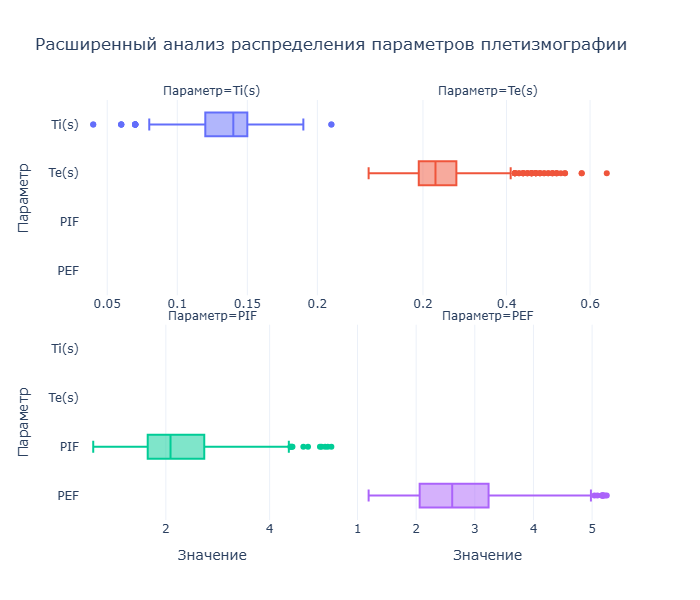

In [12]:
import sys
import subprocess
import plotly.express as px
import plotly.io as pio

if 'google.colab' not in sys.modules:
    try:
        import kaleido
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "kaleido"])

pio.renderers.default = "png"
pio.templates.default = "plotly_white"

print("--- Расчет выбросов по методу IQR ---")
for col in df.select_dtypes(include=[np.number]).columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"Параметр {col:8}: найдено {len(outliers):4} выбросов (Границы: [{lower_bound:.3f}, {upper_bound:.3f}])")

plot_cols = ['Ti(s)', 'Te(s)', 'PIF', 'PEF']
df_long = df[plot_cols].melt(var_name='Параметр', value_name='Значение')

fig = px.box(
    df_long, 
    x="Значение", 
    y="Параметр", 
    color="Параметр",
    facet_col="Параметр",
    facet_col_wrap=2, 
    points="outliers", 
    title="Расширенный анализ распределения параметров плетизмографии"
)

fig.update_xaxes(matches=None, showticklabels=True)
fig.update_layout(showlegend=False, height=600)
fig.show()

Построение диаграмм размаха через фасеты со свободными шкалами позволило наглядно визуализировать распределения признаков разного масштаба. Временные метрики (`Ti`, `Te`) и объемные показатели сигналов (`PIF`, `PEF`) успешно разделены, исключая сжатие боксов. Обнаруженные по критерию IQR математические выбросы носят легитимный биологический характер (интенсивные вздохи, задержки дыхания мышей под внешним воздействием) и не являются техническим браком прибора.

## 5. Корреляционный анализ

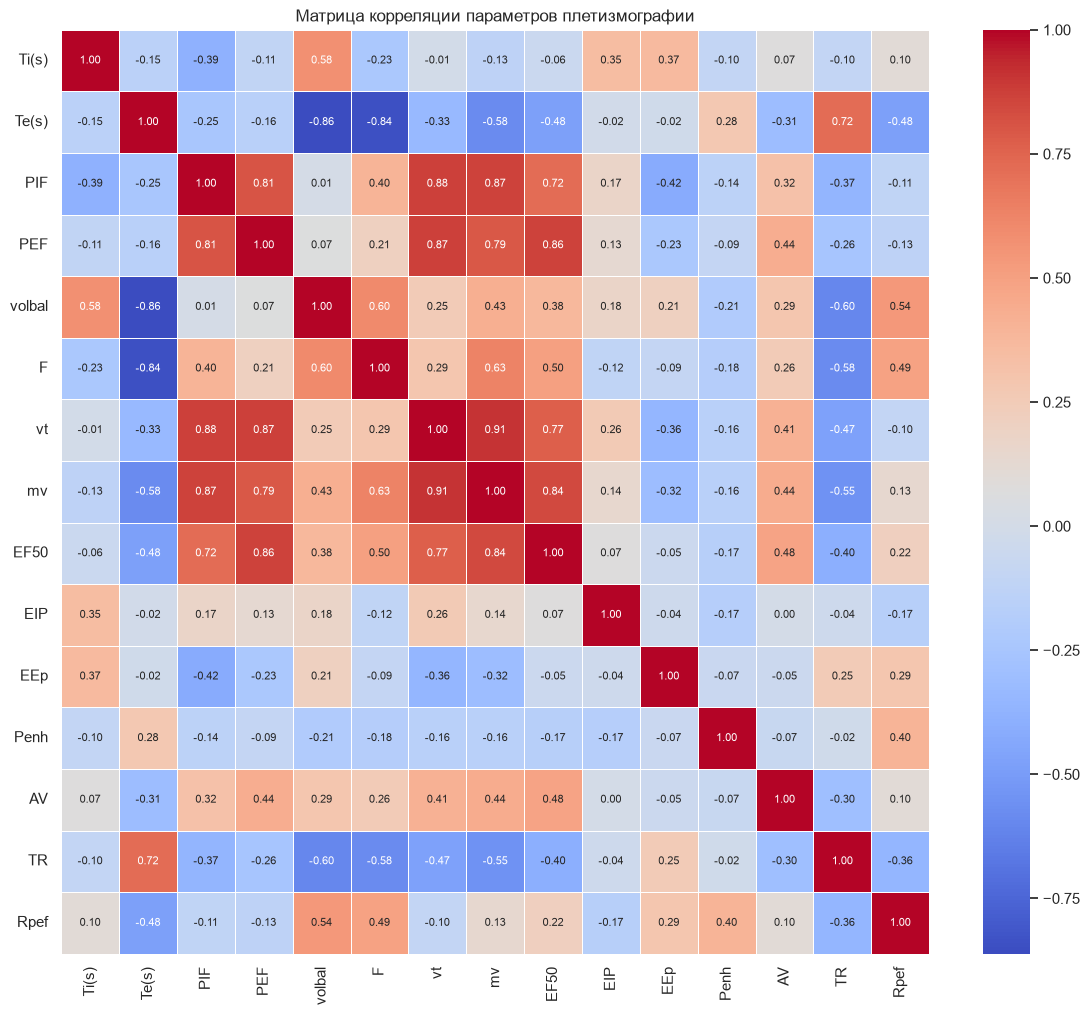

In [10]:
plt.figure(figsize=(14, 12))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, annot_kws={'size': 8})
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.title('Матрица корреляции параметров плетизмографии')
plt.show()

Тепловая карта подтверждает сильные физиологические связи между зависимыми метриками вдоха и выдоха. Обнаружена экстремально высокая линейная взаимосвязь между пиковыми потоками и средними объемами, что подтверждает физический смысл собираемых датчиками параметров и верифицирует внутреннюю непротиворечивость структуры данных.

## Заключение и выводы
1. **Структура и целостность:** Размерность выборки и типы данных верифицированы. Параметры исходно представлены в валидных числовых форматах, пропусков в данных не обнаружено.
2. **Анализ аномалий (EIp):** Алгоритм IQR зафиксировал 399 отклонений в колонке EIp. Границы [0.020, 0.020] указывают на константный характер признака, а «выбросы» вызваны минимальным округлением прибора.
3. **Аномалии и вариативность (Penh, AV, TR):** Выбросы в параметрах Penh, AV и TR отражают естественную физиологическую вариативность пиковых объемов дыхания мышей. Данные строки решено сохранить для полноты картины.
4. **Валидность и корреляции:** Наличие сильных корреляционных связей между физиологически зависимыми метриками вдоха и выдоха подтверждает внутреннюю логику и высокое качество собранных прибором данных.
5. **Следующие шаги:** В рамках дальнейшего проектирования пайплайна данных планируется провести нормализацию признаков с длинными хвостами распределений и выполнить отбор наиболее информативных параметров для устранения мультиколлинеарности.